AUTOR: MARTIN EZEQUIEL DEL VALLE

# ✅ ETAPA 1 - Recopilación y preparación de los datos.

1️⃣ Subir los archivos

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving clientes.csv to clientes.csv
Saving marketing.csv to marketing.csv
Saving ventas.csv to ventas.csv


In [ ]:
import pandas as pd

ventas = "https://drive.google.com/uc?id=1_5i6_-Dwu7tyj5qQsKcPDeT8iYoRTjEA"
clientes = "https://drive.google.com/uc?id=1cJRTplXYkuNq1LXkLtRD1ytECgwToT77"
marketing = "https://drive.google.com/uc?id=1Y0yElnxTUXLecQhXh_mmWbNmiBbJWxy6"

ventas = pd.read_csv(ventas)
clientes = pd.read_csv(clientes)
marketing = pd.read_csv(marketing)

#Visualizamos primeras 5 filas
print("Ventas:")
display(ventas.head())

print("\nClientes:")
display(clientes.head())

print("\nMarketing:")
display(marketing.head())


Ventas:


,id_venta,producto,precio,cantidad,fecha_venta,categoria
0,792,Cuadro decorativo,$69.94,5.0,02/01/2024,Decoración
1,811,Lámpara de mesa,$105.10,5.0,02/01/2024,Decoración
2,1156,Secadora,$97.96,3.0,02/01/2024,Electrodomésticos
3,1372,Heladera,$114.35,8.0,02/01/2024,Electrodomésticos
4,1546,Secadora,$106.21,4.0,02/01/2024,Electrodomésticos



Clientes:


,id_cliente,nombre,edad,ciudad,ingresos
0,1,Aloysia Screase,44,Mar del Plata,42294.68
1,2,Kristina Scaplehorn,25,Posadas,24735.04
2,3,Filip Castagne,50,Resistencia,35744.85
3,4,Liuka Luard,39,Bahía Blanca,27647.96
4,5,Dore Cockshtt,28,Rosario,28245.65



Marketing:


,id_campanha,producto,canal,costo,fecha_inicio,fecha_fin
0,74,Adorno de pared,TV,4.81,20/03/2024,03/05/2024
1,12,Tablet,RRSS,3.40,26/03/2024,13/05/2024
2,32,Lámpara de mesa,Email,5.54,28/03/2024,20/04/2024
3,21,Smartphone,RRSS,6.37,29/03/2024,16/05/2024
4,58,Alfombra,Email,4.25,31/03/2024,05/05/2024


2️⃣ Creamos un script básico que calcule las ventas mensuales utilizando variables y operadores.

In [3]:
import pandas as pd

#Límpieza general de datos

ventas['precio'] = ventas['precio'].astype(str).str.replace(',', '').str.replace('$', '').str.strip()
ventas['cantidad'] = ventas['cantidad'].astype(str).str.strip()

#Convertir el dato

for col in ['precio','cantidad']:
  ventas[col] = pd.to_numeric(ventas[col], errors='coerce')

#Se elimina las filas con datos inválidos
ventas = ventas.dropna(subset=['precio', 'cantidad'])

ventas['cantidad'] = ventas['cantidad'].astype(int)

#Convertir columna fecha_venta
ventas['fecha_venta'] = pd.to_datetime(ventas['fecha_venta'], errors='coerce')
ventas = ventas.dropna(subset=['fecha_venta'])

#Se crea columna 'mes' y 'año' para agrupar
ventas['mes'] = ventas['fecha_venta'].dt.month
ventas['año'] = ventas['fecha_venta'].dt.year
ventas['mes_año'] = ventas['fecha_venta'].dt.to_period('M')

#Se calculan ventas
ventas['total_venta'] = ventas['precio'] * ventas['cantidad']

#Agrupar
ventas_mensuales = ventas.groupby('mes_año')['total_venta'].sum().sort_index()

#Mostrar
print("Ventas mensuales:")
display(ventas_mensuales)



Ventas mensuales:


mes_año
2024-01    35813.42
2024-02    62419.50
2024-03    41350.64
2024-04    40841.22
2024-05    49496.33
2024-06    50875.32
2024-07    58644.45
2024-08    52239.92
2024-09    42206.39
2024-10    49905.12
2024-11    54428.57
2024-12    44756.34
Freq: M, Name: total_venta, dtype: float64

3️⃣ Estructura de datos. Se almacenan los datos de ventas (producto, precio, cantidad)

In [4]:
# Convertir el DataFrame en lista de diccionarios
ventas_dict = ventas.to_dict(orient="records")

# se crea un nuevo diccionario para agrupar las ventas por producto
ventas_agrupadas = {}

for v in ventas_dict:
    producto = v['producto']
    total = v['precio'] * v['cantidad']

    # Si el producto ya existe, acumula la cantidad y el total
    if producto in ventas_agrupadas:
        ventas_agrupadas[producto]['cantidad'] += v['cantidad']
        ventas_agrupadas[producto]['total_venta'] += total
    else:
        ventas_agrupadas[producto] = {
            'precio': v['precio'],
            'cantidad': v['cantidad'],
            'total_venta': total
        }

# Mostrar ventas agrupadas por producto
print("\nVentas agrupadas por producto:")
for producto, cantidad in ventas_agrupadas.items():
    print(f"Total de {producto}: {cantidad['cantidad']} unidades - Total ${cantidad['total_venta']:.2f}")



Ventas agrupadas por producto:
Total de Cuadro decorativo: 287 unidades - Total $20720.84
Total de Lámpara de mesa: 439 unidades - Total $32901.91
Total de Secadora: 313 unidades - Total $21640.83
Total de Heladera: 121 unidades - Total $9482.73
Total de Horno eléctrico: 253 unidades - Total $17620.72
Total de Plancha de vapor: 317 unidades - Total $21761.04
Total de Proyector: 281 unidades - Total $20848.63
Total de Rincón de plantas: 278 unidades - Total $19002.03
Total de Candelabro: 59 unidades - Total $3521.64
Total de Aspiradora: 260 unidades - Total $20166.93
Total de Freidora eléctrica: 223 unidades - Total $16697.02
Total de Tablet: 141 unidades - Total $8869.23
Total de Cortinas: 273 unidades - Total $20579.21
Total de Adorno de pared: 295 unidades - Total $20810.59
Total de Jarrón decorativo: 287 unidades - Total $20432.32
Total de Lavadora: 255 unidades - Total $18399.03
Total de Auriculares: 395 unidades - Total $33126.87
Total de Cámara digital: 196 unidades - Total $133

4️⃣ Análisis

In [6]:
#Informe general
print(ventas.info())
print(clientes.info())
print(marketing.info())

#Estadisticas
print(ventas.describe())
print(clientes.describe())
print(marketing.describe())

#Columnas
print(ventas.columns)
print(clientes.columns)
print(marketing.columns)

#Valores unico
print(ventas.nunique())

#Ver distribución de los productos
print(ventas['producto'].value_counts())


<class 'pandas.DataFrame'>
Index: 1189 entries, 0 to 2888
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   id_venta     1189 non-null   int64         
 1   producto     1189 non-null   str           
 2   precio       1189 non-null   float64       
 3   cantidad     1189 non-null   int64         
 4   fecha_venta  1189 non-null   datetime64[us]
 5   categoria    1189 non-null   str           
 6   mes          1189 non-null   int32         
 7   año          1189 non-null   int32         
 8   mes_año      1189 non-null   period[M]     
 9   total_venta  1189 non-null   float64       
dtypes: datetime64[us](1), float64(2), int32(2), int64(2), period[M](1), str(2)
memory usage: 92.9 KB
None
<class 'pandas.DataFrame'>
RangeIndex: 567 entries, 0 to 566
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id_cliente  567 non-null    int64 

5️⃣ Calidad de datos (Tratamiento de valores Nulos y duplicados)

In [7]:

#Ventas
#Valores nulos
print("="*30)
print("\nValores nulos en Ventas:")
print(ventas.isnull().sum())

#Valores duplicados
print("\nValores duplicados en Ventas:")
print(ventas.duplicated().sum())
print("="*30)

#Clientes
print("\nValores nulos en Clientes:")
print(clientes.isnull().sum())

print("\nValores duplicados en Clientes:")
print(clientes.duplicated().sum())
print("="*30)

#Marketing
print("\nValores nulos en Marketing:")
print(marketing.isnull().sum())

print("\nValores duplicados en Marketing:")
print(marketing.duplicated().sum())
print("="*30)


Valores nulos en Ventas:
id_venta       0
producto       0
precio         0
cantidad       0
fecha_venta    0
categoria      0
mes            0
año            0
mes_año        0
total_venta    0
dtype: int64

Valores duplicados en Ventas:
35

Valores nulos en Clientes:
id_cliente    0
nombre        0
edad          0
ciudad        0
ingresos      0
dtype: int64

Valores duplicados en Clientes:
0

Valores nulos en Marketing:
id_campanha     0
producto        0
canal           0
costo           0
fecha_inicio    0
fecha_fin       0
dtype: int64

Valores duplicados en Marketing:
0


# ✅ ETAPA 2 - Preprocesamiento y limpieza

1️⃣ Limpieza

In [8]:
#Eliminar duplicados
filas_antes = len(ventas)
ventas = ventas.drop_duplicates()
filas_despues = len(ventas)

#Eliminar nulos
ventas = ventas.dropna(subset=['precio', 'cantidad'])

print("Filas antes:", filas_antes)
print("Filas después:", len(ventas))

Filas antes: 1189
Filas después: 1154


2️⃣ Crear una tabla de productos de alto rendimiento

In [9]:

#Alto rendimiento
rendimiento = ventas['total_venta'].mean()
alto_rendimiento = ventas[ventas['total_venta'] > rendimiento]

print("Rendimiento promedio:", rendimiento)
print("Productos con alto rendimiento:")
print(alto_rendimiento)
print(alto_rendimiento.index) # Para ver los indices del DataFrame Original
print(alto_rendimiento.index.tolist()) # Convertir los indices en una lista
print("Cantidad de productos de alto rendimiento:",len(alto_rendimiento))

Rendimiento promedio: 491.3585875216638
Productos con alto rendimiento:
      id_venta            producto  precio  cantidad fecha_venta  \
1          811     Lámpara de mesa  105.10         5  2024-02-01   
3         1372            Heladera  114.35         8  2024-02-01   
7         2959           Proyector   88.17         9  2024-02-01   
8          318   Rincón de plantas   79.86        11  2024-03-01   
9          419          Candelabro   66.11         8  2024-03-01   
...        ...                 ...     ...       ...         ...   
2877      1975            Lavadora  116.55         6  2024-11-12   
2878      2144         Auriculares  100.70        11  2024-11-12   
2881       128   Rincón de plantas   96.21         6  2024-12-12   
2883      1414          Aspiradora   85.23        10  2024-12-12   
2884      1471  Freidora eléctrica   83.48         8  2024-12-12   

              categoria  mes   año  mes_año  total_venta  
1            Decoración    2  2024  2024-02       52

3️⃣ AGREGACIÓN

In [10]:
ventas_categoria = ventas.groupby('categoria',as_index=False)['total_venta'].sum()
print("Ventas por categoría:")
print(ventas_categoria)

Ventas por categoría:
           categoria  total_venta
0         Decoración    189625.79
1  Electrodomésticos    192545.57
2        Electrónica    184856.45


4️⃣ INTEGRACIÓN DE DATOS

In [11]:
df_integrado = ventas.merge(marketing, on='producto', how='left')
print("Dataset integrado:")
display(df_integrado.head())

Dataset integrado:


,id_venta,producto,precio,cantidad,fecha_venta,categoria,mes,año,mes_año,total_venta,id_campanha,canal,costo,fecha_inicio,fecha_fin
0,792,Cuadro decorativo,69.94,5,2024-02-01,Decoración,2,2024,2024-02,349.7,1,RRSS,5.27,27/04/2024,04/06/2024
1,792,Cuadro decorativo,69.94,5,2024-02-01,Decoración,2,2024,2024-02,349.7,31,Email,5.28,15/08/2024,12/09/2024
2,792,Cuadro decorativo,69.94,5,2024-02-01,Decoración,2,2024,2024-02,349.7,61,TV,5.30,05/11/2024,23/12/2024
3,811,Lámpara de mesa,105.10,5,2024-02-01,Decoración,2,2024,2024-02,525.5,32,Email,5.54,28/03/2024,20/04/2024
4,811,Lámpara de mesa,105.10,5,2024-02-01,Decoración,2,2024,2024-02,525.5,2,RRSS,5.88,30/05/2024,29/06/2024


# ✅ ETAPA 3 - Análisis de Datos

1️⃣ Estadistica descriptica

In [12]:
# Estadistica descriptiva
ventas['total_venta'] = ventas['precio'] * ventas['cantidad']
print("total_venta:" ,ventas['total_venta'].sum())
# Media
media = ventas['total_venta'].mean()
print("Media:", media)

# Mediana
mediana = ventas['total_venta'].median()
print("Mediana:", mediana)

# Moda
moda = ventas['total_venta'].mode()
print("Moda:", moda)

total_venta: 567027.81
Media: 491.3585875216638
Mediana: 418.595
Moda: 0      64.37
1     106.32
2     111.04
3     196.92
4     217.36
5     233.94
6     344.85
7     345.72
8     349.14
9     374.00
10    928.70
Name: total_venta, dtype: float64


In [13]:
# Medidas de dispersión
# Desviación Estándar
desviacion_estandar = ventas['total_venta'].std()
print("Desviación Estándar:", desviacion_estandar) # Indica cuan alejado estan las ventas del promedio

# Varianza
varianza = ventas['total_venta'].var()
print("Varianza:", varianza) # Variabilidad de los datos.
## Conclusión: La varianza resultante representa una dispersion considerable respecto del promedio

# Rango
rango = ventas['total_venta'].max() - ventas['total_venta'].min()
print("Rango:", rango)

Desviación Estándar: 335.8459264353328
Varianza: 112792.48630320697
Rango: 1460.2900000000002


2️⃣ Análisis exploratorio de datos (EDA)

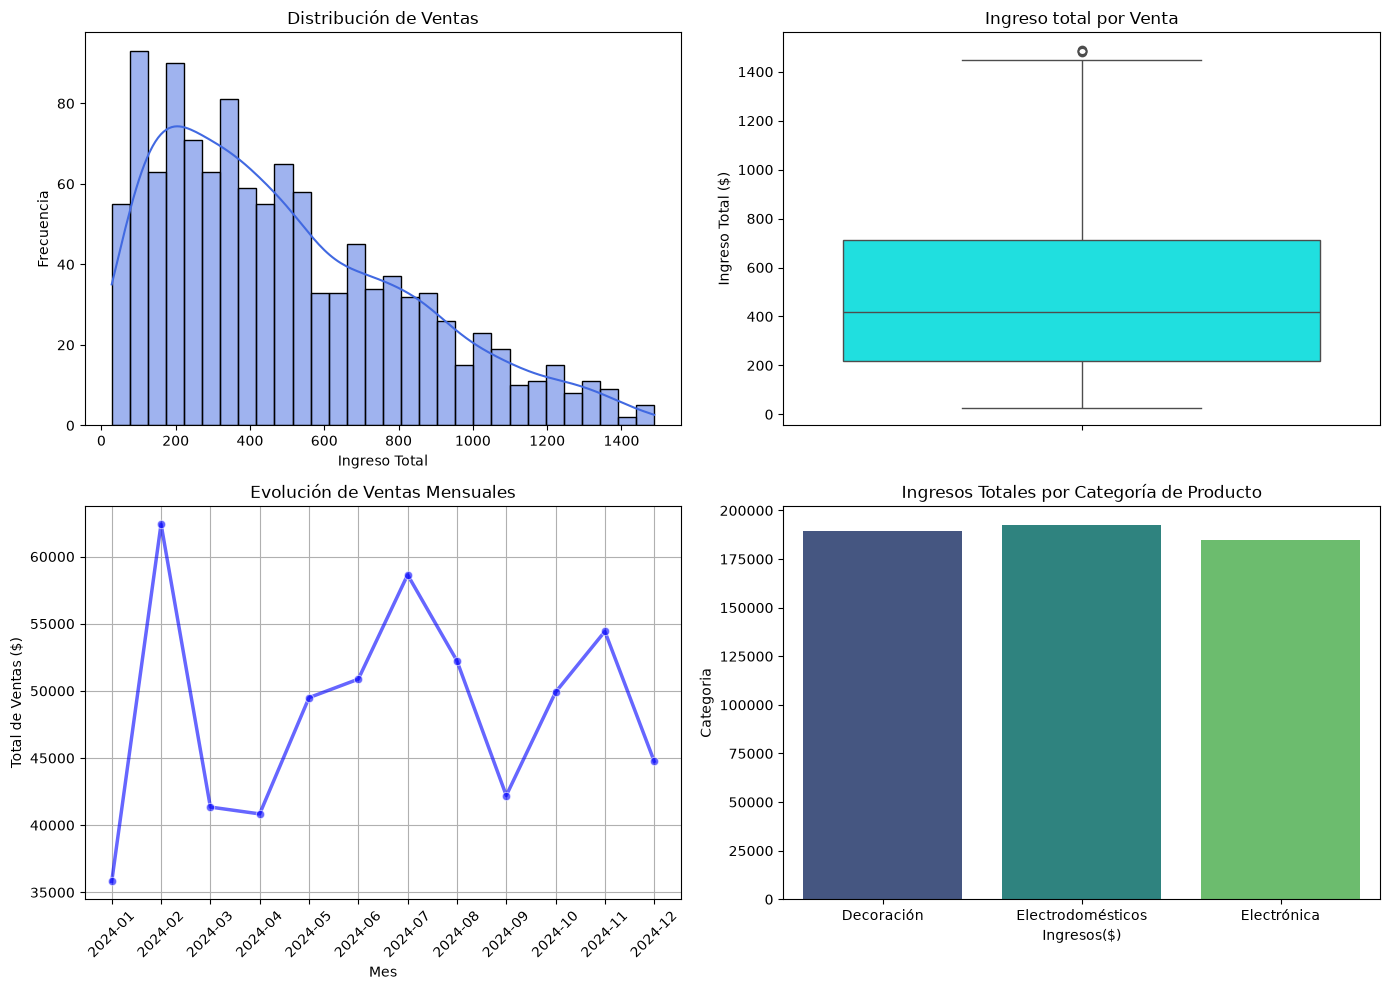

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Definimos el cuadrante para las graficas

fig, axes = plt.subplots(2,2, figsize=(14, 10))


# Gráfico de Histograma de ventas

sns.histplot(ventas["total_venta"], bins=30, color='royalblue', edgecolor='black', kde=True, ax=axes[0,0])
axes[0,0].set_title("Distribución de Ventas")
axes[0,0].set_xlabel("Ingreso Total")
axes[0,0].set_ylabel("Frecuencia")

# Gráfico de Boxplot de ventas

sns.boxplot(y=ventas["total_venta"], color='cyan', ax=axes[0,1])
axes[0, 1].set_title("Ingreso total por Venta")
axes[0, 1].set_ylabel("Ingreso Total ($)")

# Gráfico de Lineas. Visualizamos las de ventas por mes.
ventas_categoria = ventas.groupby("categoria")["total_venta"].sum().reset_index()
#ventas["mes"] = ventas["fecha_venta"].dt.month
#ventas_mes = ventas.groupby("mes")["total_venta"].sum().reset_index()
ventas_mensuales_df = ventas_mensuales.reset_index()

ventas_mensuales_df['mes_año'] = (
    ventas_mensuales_df['mes_año']
    .astype(str)
)

sns.lineplot(data= ventas_mensuales_df, x='mes_año', y='total_venta', marker='o', color='blue', alpha=0.6, linewidth=2.5, ax=axes[1,0])
axes[1, 0].set_title('Evolución de Ventas Mensuales')
axes[1, 0].set_xlabel('Mes')
axes[1, 0].set_ylabel('Total de Ventas ($)')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].grid(True)

# Gráfico de barras. Visualizamos ventas por categoria.
sns.barplot(data=ventas_categoria, x='categoria', y='total_venta', palette='viridis', hue='categoria', legend=False, ax=axes[1, 1])
axes[1, 1].set_title('Ingresos Totales por Categoría de Producto')
axes[1, 1].set_xlabel('Ingresos($)')
axes[1, 1].set_ylabel('Categoria')

plt.tight_layout()
plt.show()

#
#Ayuda a identificar:
#tendencias
#crecimiento o disminución de ventas
#meses de mayor venta, menor venta

3️⃣ Correlación y Consolidación de datos


Matriz de correlación:
               precio  cantidad  total_venta
precio       1.000000 -0.019529     0.557043
cantidad    -0.019529  1.000000     0.765083
total_venta  0.557043  0.765083     1.000000

Vista previa del dataset final consolidado:
   id_venta           producto  precio  cantidad  total_venta fecha_venta  \
0       792  Cuadro decorativo   69.94         5        349.7  2024-02-01   
1       792  Cuadro decorativo   69.94         5        349.7  2024-02-01   
2       792  Cuadro decorativo   69.94         5        349.7  2024-02-01   
3       811    Lámpara de mesa  105.10         5        525.5  2024-02-01   
4       811    Lámpara de mesa  105.10         5        525.5  2024-02-01   

    categoria  mes  canal  costo  
0  Decoración    2   RRSS   5.27  
1  Decoración    2  Email   5.28  
2  Decoración    2     TV   5.30  
3  Decoración    2  Email   5.54  
4  Decoración    2   RRSS   5.88  


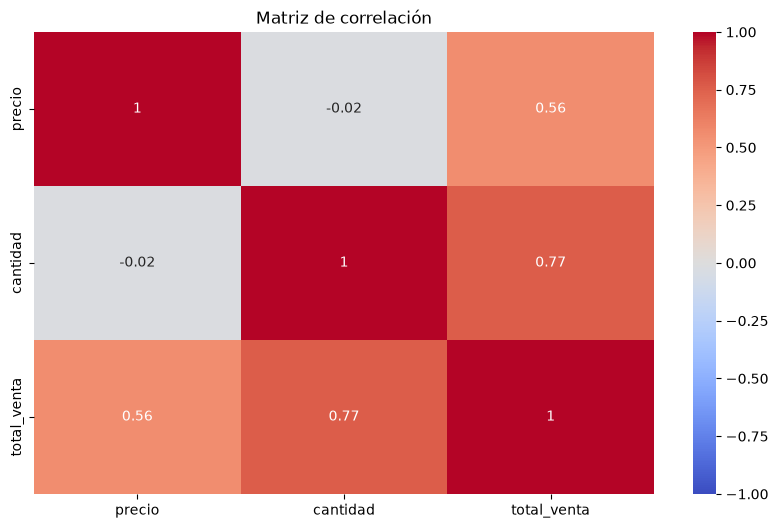

In [15]:
import pandas as pd
import numpy as np

# 3. Correlación entre variables
correlacion = ventas[['precio', 'cantidad', 'total_venta']].corr()
print("\nMatriz de correlación:")
print(correlacion)

# 4. Consolidación del dataset final
# Conservamos columnas clave + las unidas de marketing
columnas_finales = [
    'id_venta', 'producto', 'precio', 'cantidad', 'total_venta',
    'fecha_venta', 'categoria', 'mes',
    'canal', 'costo'
]

ventas_final = df_integrado[columnas_finales].copy()

# Mostramos una muestra consolidada
print("\nVista previa del dataset final consolidado:")
print(ventas_final.head())

plt.figure(figsize=(10, 6))
sns.heatmap(correlacion, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Matriz de correlación")
plt.show()

# ✅ ETAPA 4 - Visualización de datos


1️⃣ Visualización con Matplotlib

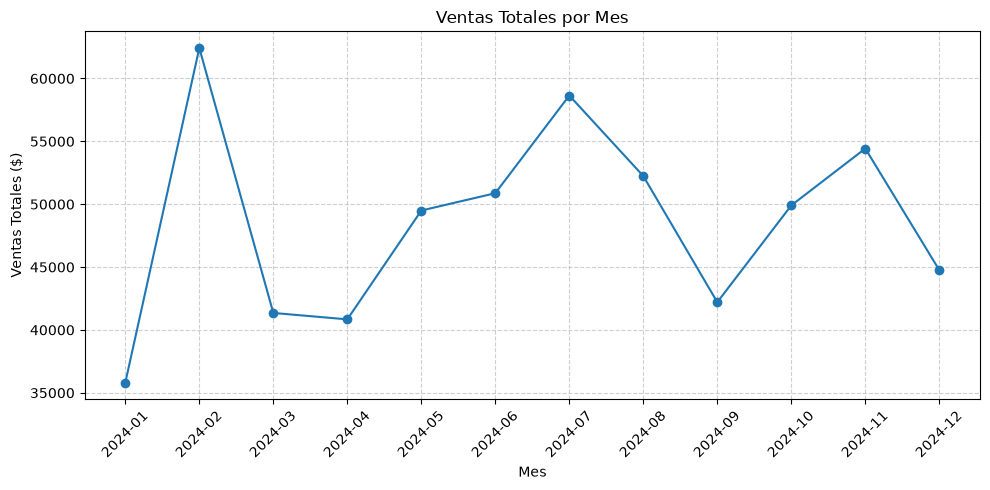

In [16]:
import matplotlib.pyplot as plt

#-------------------------------------------------------
# 1. Gráfico de líneas: Evolución de ventas mensuales
#-------------------------------------------------------

# ventas_mensuales es una Serie con PeriodIndex como índice
plt.figure(figsize=(10, 5))

plt.plot(ventas_mensuales.index.astype(str), ventas_mensuales.values, marker='o')
plt.title('Ventas Totales por Mes')
plt.xlabel('Mes')
plt.ylabel('Ventas Totales ($)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


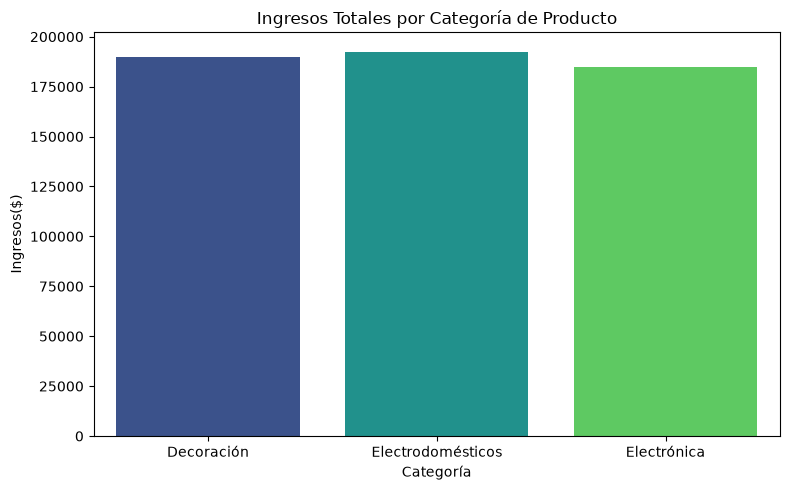

In [17]:
#-------------------------------------------------
# 2. Gráfico de barras: Ingresos por categoría
#-------------------------------------------------
resumen_categoria = ventas.groupby('categoria')['total_venta'].sum().reset_index()
plt.figure(figsize=(8, 5))
#ventas_categoria es una Serie (index: categoría, values: total_venta)
#plt.bar(ventas_categoria.index, ventas_categoria.values, color='viridis',hue=categoria)
sns.barplot(x='categoria', y='total_venta', palette='viridis', hue='categoria', legend=False, saturation=1.0, data=resumen_categoria)
plt.title('Ingresos Totales por Categoría de Producto')
plt.xlabel('Categoría')
plt.ylabel('Ingresos($)')
#plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


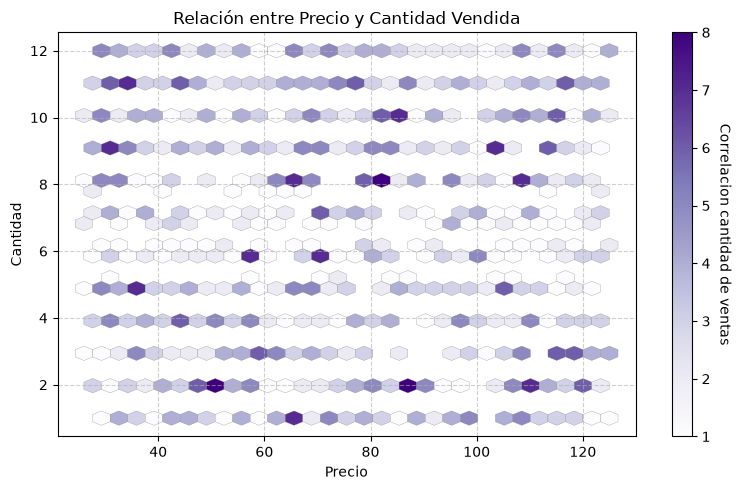

In [18]:
#---------------------------------------------
# 3. Dispersión: precio vs cantidad vendida
#---------------------------------------------
plt.figure(figsize=(8, 5))
#plt.scatter(ventas['precio'], ventas['cantidad'], alpha=0.6)
plt.hexbin(ventas['precio'], ventas['cantidad'], gridsize=30, cmap='Purples', mincnt=1, edgecolors='grey',linewidths=0.2)
cbar=plt.colorbar()
cbar.set_label('Correlacion cantidad de ventas', rotation=270, labelpad=15)
plt.title('Relación entre Precio y Cantidad Vendida')
plt.xlabel('Precio')
plt.ylabel('Cantidad')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

2️⃣ Visualización con seaborn

---



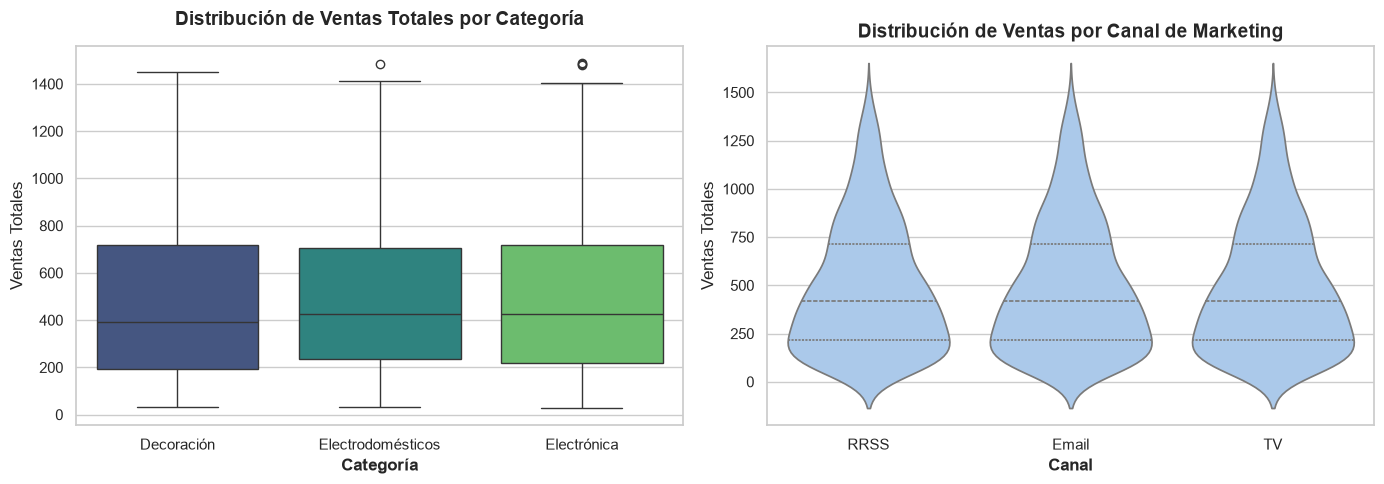

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

# Estilo general
sns.set(style="whitegrid", palette="pastel")

fig, axes = plt.subplots(1, 2, figsize=(14,5) )

#---------------------------------------------------
# Gráfico 1: Boxplot - Ventas por categoria
# --------------------------------------------------
sns.boxplot(x='categoria', y='total_venta', data=ventas, hue='categoria', palette='viridis', ax=axes[0])
axes[0].set_title('Distribución de Ventas Totales por Categoría', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Categoría', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Ventas Totales', fontsize=12)

# ------------------------------------------------------------------------
# Gráfico 2: Violin plot - efecto del canal de marketing sobre ventas
# ------------------------------------------------------------------------
sns.violinplot(x='canal', y='total_venta', data=df_integrado, inner='quartile', ax=axes[1])
axes[1].set_title('Distribución de Ventas por Canal de Marketing', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Canal', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Ventas Totales')
plt.tight_layout()
plt.show()

3️⃣ Visualización interactiva con Plotly

Por último construiremos un dashboard interactivo que combine múltiples visualizaciones, permitiendo al usuario explorar los datos dinámicamente.

In [20]:
# ===============================================================
# CREACIÓN DE DASHBOARD INTERACTIVO CON PLOTLY Y FILTRO DINÁMICO
# ===============================================================

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd

# ---------------------------------------
# PREPARACIÓN Y AGREGACIÓN DE DATOS
# ---------------------------------------
# Agrupamos las ventas por período temporal, sumamos los ingresos y transformamos el indice a string para facilitar el renderizado.
# display (ventas.head())
ventas_mensuales_df = ventas.groupby(ventas['fecha_venta'].dt.to_period('M'))['total_venta'].sum().reset_index()
ventas_mensuales_df['fecha_venta'] = ventas_mensuales_df['fecha_venta'].astype(str)

# Agregamos los ingresos acumulados por categoría de producto.
resumen_cat = ventas.groupby('categoria')['total_venta'].sum().reset_index()

# Agregamos los ingresos por producto
resumen_prod = ventas.groupby('producto')['total_venta'].sum().reset_index().sort_values('total_venta', ascending=True)

# -----------------------------
# ESTRUCTURA DE SUBPLOTS
# -----------------------------
# Inicializamos una figura con subgráficos de 2 filas y 2 columnas, definimos los títulos y espacios
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        '1. Evolución Ingresos Mensuales',
        '2. Ingresos Totales por Categoría',
        '3. Precio vs Cantidad Vendida',
        '4. Productos más vendidos'
    ),
    vertical_spacing=0.22,
    horizontal_spacing=0.25
)

# -------------------------------------------------------------------
# CREAMOS LAS TRAZAS PARA LOS FILTROS INTERACTIVOS - DROPDOWN
# -------------------------------------------------------------------

# Creamos las trazas principales del dashboard

# Gráfico 1: Línea Temporal
fig.add_trace(
    go.Scatter(
        x=ventas_mensuales_df['fecha_venta'],
        y=ventas_mensuales_df['total_venta'],
        mode='lines+markers',
        name='Ingresos Mensuales (Total)',
        line=dict(color='#008B8B', width=3),
        marker=dict(size=8),                     # Tamaño de los marcadores circulares
        visible=True                             # Define la traza como visible al cargar el dashboard
    ),
    row=1, col=1
)

# Gráfico 2: Barras por Categoría General
colores_viridis = px.colors.sequential.Viridis[:len(resumen_cat)]
fig.add_trace(
    go.Bar(
        x=resumen_cat['categoria'],
        y=resumen_cat['total_venta'],
        name='Categorías (Total)',
        marker=dict(color=colores_viridis),
        visible=True
    ),
    row=1, col=2
)

# Gráfico 3: Dispersión de Precio vs Cantidad
fig.add_trace(
    go.Scatter(
        x=ventas['precio'],
        y=ventas['cantidad'],
        mode='markers',
        name='Transacciones (Total)',
        marker=dict(
            size=4,                          # Configuramos un tamaño reducido de los puntos
            color=ventas['total_venta'],
            colorscale='Teal',
            showscale=True,                  # Muestra la barra de referencia colorbar
            colorbar=dict(title="Ingresos ($)", x=0.40, len=0.50, y=0.22, thickness=12), # Ajustamos posición y título de la barra de color
            opacity=0.85,                    # Aplicamos ligera transparencia para apreciar los puntos superpuestos
            line=dict(width=0.6, color='rgba(50,50,50,0.4)') # Borde sutil en cada punto (Mejoró el aspecto visual)
        ),
        visible=True
    ),
    row=2, col=1
)

# Gráfico 4: Barras Horizontales
fig.add_trace(
    go.Bar(
        x=resumen_prod['total_venta'],
        y=resumen_prod['producto'],
        orientation='h',                  # Define orientción horizontal del gráfico de barras
        name='Productos (Total)',
        marker=dict(color='#9b59b6'),
        visible=True
    ),
    row=2, col=2
)

# --- TRAZAS FILTRADAS POR CATEGORÍA ---

# Definimos un diccionario con los colores específicos para cada categoría
colores_por_categoria = {
    'Decoración': '#8e44ad',        # Morado
    'Electrodomésticos': '#16a085', # Turquesa
    'Electrónica': '#e67e22' #Naranja
}

categorias_unicas = ventas['categoria'].unique()

for cat in categorias_unicas:
    # Obtenemos el color asignado a esta categoría (o un gris por defecto si no existe)
    color_cat = colores_por_categoria.get(cat, '#e74c3c')

    df_cat_ventas = ventas[ventas['categoria'] == cat]
    df_cat_mensual = df_cat_ventas.groupby(df_cat_ventas['fecha_venta'].dt.to_period('M'))['total_venta'].sum().reset_index()
    df_cat_mensual['fecha_venta'] = df_cat_mensual['fecha_venta'].astype(str)
    df_cat_prod = df_cat_ventas.groupby('producto')['total_venta'].sum().reset_index().sort_values('total_venta', ascending=True)

    # Traza de línea temporal filtrada
    fig.add_trace(
        go.Scatter(
            x=df_cat_mensual['fecha_venta'],
            y=df_cat_mensual['total_venta'],
            mode='lines+markers',
            name=f'Ingresos - {cat}',
            line=dict(color=color_cat, width=3), # <--- Usa el color de la categoría
            marker=dict(size=8),
            visible=False
        ),
        row=1, col=1
    )

    # Traza de barra de categoría única
    fig.add_trace(
        go.Bar(
            x=[cat],
            y=[df_cat_ventas['total_venta'].sum()],
            name=f'Categoría - {cat}',
            marker=dict(color=color_cat), # <--- Usa el color de la categoría
            visible=False
        ),
        row=1, col=2
    )

    # Traza de dispersión filtrada por categoría

    fig.add_trace(
        go.Scatter(
            x=df_cat_ventas['precio'],
            y=df_cat_ventas['cantidad'],
            mode='markers',
            name=f'Transacciones - {cat}',
            marker=dict(
                size=7,
                color=df_cat_ventas['total_venta'],
                colorscale='Viridis',
                showscale=False,
                opacity=0.85,
                line=dict(width=0.6, color='rgba(50,50,50,0.4)')
            ),
            visible=False
        ),
        row=2, col=1
    )

    # Traza de productos filtrados por categoría
    fig.add_trace(
        go.Bar(
            x=df_cat_prod['total_venta'],
            y=df_cat_prod['producto'],
            orientation='h',
            name=f'Productos - {cat}',
            marker=dict(color=color_cat), # <--- Usa el color de la categoría
            visible=False
        ),
        row=2, col=2
    )

# ------------------------------------------------------------
# CONFIGURACIÓN DE LOS BOTONES DEL MENÚ DESPLEGABLE
# ------------------------------------------------------------
total_trazas_base = 4
buttons = []

# Botón 1: Muestra la vista general
visibilidad_global = [True] * total_trazas_base + [False] * (len(categorias_unicas) * 4)
buttons.append(dict(
    method="update",
    label="🔍 Todas las Categorías",
    args=[{"visible": visibilidad_global},
          {"title": "<b>Dashboard Rendimiento Comercial - Vista General</b>"}]
))

# Botones dinámicos para cada categoría individual
for i, cat in enumerate(categorias_unicas):
    # Creamos una lista donde solo se encienden la traza seleccionada
    visibilidad_cat = [False] * len(fig.data)
    idx_inicio = total_trazas_base + (i * 4)
    for j in range(4):
        visibilidad_cat[idx_inicio + j] = True

    buttons.append(dict(
        method="update",
        label=f"📂 Categoría: {cat}",
        args=[{"visible": visibilidad_cat},
              {"title": f"<b>Dashboard Comercial - Filtrado por Categoría: {cat}</b>"}]
    ))

# --------------------------------------------------------
# CONFIGURACIÓN GENERAL DEL DISEÑO (LAYOUT Y ESTÉTICA)
# --------------------------------------------------------
fig.update_layout(
    updatemenus=[
        dict(
            type="dropdown",
            direction="down",
            x=0.0,
            y=1.15,
            showactive=True,
            active=0,
            buttons=buttons,
            font=dict(size=12),
            bgcolor="white",
            bordercolor="#cbd5e1"
        )
    ],
    title_text="<b>Dashboard Rendimiento Comercial</b>",
    title_x=0.5,
    title_font=dict(size=18, color='#333333'),
    height=900,
    showlegend=False,
    paper_bgcolor='#FFFFFF',      # Fondo general exterior
    plot_bgcolor='#F4F6F9',       # Fondo interior de cada cuadrante
    margin=dict(l=130, r=50, t=130, b=80)
)

# Aplicación de marcos perimetrales y grillas limpias en los ejes
fig.update_xaxes(
    showline=True, linewidth=1, linecolor='#cbd5e1', mirror=True, gridcolor='#e2e8f0'
)
fig.update_yaxes(
    showline=True, linewidth=1, linecolor='#cbd5e1', mirror=True, gridcolor='#e2e8f0'
)

# Asignación y posicionamiento de títulos de ejes para cada gráfico individual
fig.update_xaxes(title_text="Período (Mes)", row=1, col=1, tickangle=45)
fig.update_yaxes(title_text="Ingreso Total ($)", row=1, col=1)

fig.update_xaxes(title_text="Categoría", row=1, col=2)
fig.update_yaxes(title_text="Ingresos ($)", row=1, col=2)

fig.update_xaxes(title_text="Precio Unitario ($)", row=2, col=1)
fig.update_yaxes(title_text="Cantidad Vendida", row=2, col=1)

fig.update_yaxes(title_text="Producto", row=2, col=2, side='left', tickfont=dict(size=10))
fig.update_xaxes(title_text="Ingresos Totales ($)", row=2, col=2, side='bottom')

# ------------------------------------------------------------------------------
#RENDERIZADO DEL DASHBOARD INTERACTIVO
# ------------------------------------------------------------------------------
fig.show()

# **RESUMEN EJECUTIVO**

**AUTOR:** Martin Ezequiel del Valle

**Fecha:** 07/11/2026

**Alcance del proyecto:**

El presente proyecto tuvo como objetivo analizar el desempeño comercial de la empresa SyncData mediante la integración de datos de ventas, clientes y marketing. Durante el desarrollo se realizaron tareas de limpieza, transformación, análisis exploratorio, estadístico y visualización de datos para identificar patrones de comportamiento, oportunidades de mejora y generar recomendaciones basadas en evidencia.

El análisis permitió comprender la evolución temporal de las ventas, evaluar el rendimiento de las categorías de productos, identificar los productos más rentables y medir el impacto de las campañas de marketing sobre los ingresos obtenidos.

---

## Objetivo General

Transformar datos operativos en información útil para apoyar la toma de decisiones comerciales.

## Objetivos Específicos
Analizar la evolución de las ventas durante el año.
Evaluar el rendimiento de cada categoría de productos.
Detectar productos de alto rendimiento.
Integrar datos de marketing y ventas.
Identificar patrones de comportamiento comercial.
Generar visualizaciones para facilitar la interpretación de resultados.

## Descripción de los Datos

Se trabajó con tres conjuntos de datos:

- Ventas
- Clientes
- Marketing

## Proceso de Preparación y Limpieza

Durante la etapa de calidad y preparación de datos se realizaron las siguientes tareas:

**Limpieza.**

Eliminación de registros duplicados.

Tratamiento de valores nulos.

Conversión de fechas al formato datetime.

Conversión de variables numéricas.

Normalización de nombres y formatos.

**Resultado**

Registros finales de ventas	1154 (se eliminaron registros 35 duplicados).

Categorías analizadas	3.

Productos analizados	3.

---
# Insight
Los ingresos presentan una distribución asimétrica positiva. Existe un grupo reducido de ventas de gran importe que incrementan significativamente la facturación total.

## Evolución Temporal de las Ventas
**Observaciones**
- Enero presenta uno de los niveles más bajos de ingresos.
- Febrero alcanza el pico de facturación del año.
- Marzo y abril muestran una reducción significativa.
- Julio y noviembre presentan una recuperación importante.
- Septiembre registra uno de los descensos más marcados.

**Insight de Negocio**

Existe evidencia de comportamiento estacional que puede aprovecharse para ajustar campañas promocionales y prever necesidades operativas.


## Análisis por Categoría

**Ingresos Totales por Categoría**

Electrodomésticos:	$191.255

Decoración:	$188.257

Electrónica:	$183.627

**Conclusión**
La empresa dispone de una cartera de productos diversificada y estable. Las tres categorías presentan un nivel de ingresos muy equilibrado, lo que reduce la dependencia de una única línea de negocio.

## Productos de Alto Rendimiento

Se definió como transacción de alto rendimiento aquella con ingresos superiores al promedio general de:

$487,99

**Resultado:**
490 transacciones de alto rendimiento identificadas.

**Productos destacados:**
- Smartphone.
- Batidora.
- Elementos de cerámica.

Estos productos aparecen frecuentemente entre las operaciones de mayor valor.

## Integración Ventas + Marketing

Se integraron ambas fuentes mediante la variable producto para calcular el retorno de la inversión publicitaria. Los articulos con mayor rotacion e ingresos netos:

- Auriculares con **$30,658**

- Lámpara de mesa con **$30,228**

**Insight**

Las campañas asociadas a estos productos presentan una elevada eficiencia comercial y representan oportunidades de crecimiento.

---

## **Oportunidades de Mejora**

### Área Comercial
- Incrementar promociones durante meses de menor demanda.

- Fomentar estrategias de venta cruzada.

- Potenciar categorías con mejor rendimiento.

### Área de Marketing
- Incrementar inversión en productos con mejor ROI.
- Optimizar campañas menos eficientes.
- Aplicar segmentación basada en comportamiento de compra.

### Gestión General
- Utilizar análisis predictivos para anticipar variaciones estacionales.
- Realizar monitoreo periódico de productos de alto rendimiento.

---

## **Conclusiones Finales**
El análisis demuestra que el negocio presenta una estructura comercial equilibrada y saludable. Ninguna categoría domina significativamente la facturación total, lo que reduce riesgos operativos y financieros.

La cantidad vendida se confirmó como el principal factor impulsor de los ingresos, mientras que el análisis de marketing permitió identificar productos con retornos publicitarios altamente positivos.

Finalmente, las visualizaciones desarrolladas facilitaron la identificación de patrones temporales, distribución de ingresos, comportamiento de productos y oportunidades de optimización comercial, aportando una base sólida para la toma de decisiones basada en datos.

✅ ANEXO: Link de la carpeta drive, incluye archivo de Google Colab y set de datos.
https://drive.google.com/drive/folders/1wNSGpUnBbbqdIyeakw2BI7-Fh1Vdrkx5?usp=sharing
